Import & Konfigurasi


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

FILE      = "gold_usd.csv"
COL_DATE  = "Date"
COL_PRICE = "Close_USD"

Muat Data

In [25]:
df = pd.read_csv(FILE)
df[COL_DATE] = pd.to_datetime(df[COL_DATE])
df = df.sort_values(COL_DATE).reset_index(drop=True)
print(df["Set"].unique())
print(df.info())

['train' 'test']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209 entries, 0 to 208
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       209 non-null    datetime64[ns]
 1   Close_USD  209 non-null    float64       
 2   Set        209 non-null    object        
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 5.0+ KB
None


Fitur lag + split


In [26]:
for i in range(1, 4):
    df[f"lag_{i}"] = df[COL_PRICE].shift(i)
df = df.dropna().reset_index(drop=True)

features = ["lag_1", "lag_2", "lag_3"]

train = df[df["Set"] == "train"]
test  = df[df["Set"] == "test"]
print("Train:", len(train), "| Test:", len(test))
print("Periode uji:", test[COL_DATE].min().date(), "s/d", test[COL_DATE].max().date())

X_train, y_train = train[features], train[COL_PRICE]
X_test,  y_test  = test[features],  test[COL_PRICE]

Train: 184 | Test: 22
Periode uji: 2026-10-01 s/d 2026-10-30


model + evaluasi

In [27]:
def evaluasi(nama, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"{nama:<20} MAE={mae:8.2f}  RMSE={rmse:8.2f}")
    return y_pred

pred_naive = evaluasi("Naive (kemarin)", y_test, X_test["lag_1"])

lr = LinearRegression().fit(X_train, y_train)
pred_lr = evaluasi("Linear Regression", y_test, lr.predict(X_test))

rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train, y_train)
pred_rf = evaluasi("Random Forest", y_test, rf.predict(X_test))

print("Koefisien LR:", dict(zip(features, lr.coef_.round(4))),
      "| intercept:", round(lr.intercept_, 4))

Naive (kemarin)      MAE=   37.52  RMSE=   48.00
Linear Regression    MAE=   38.13  RMSE=   51.58
Random Forest        MAE=   44.18  RMSE=   56.06
Koefisien LR: {'lag_1': np.float64(0.9747), 'lag_2': np.float64(-0.0981), 'lag_3': np.float64(0.0949)} | intercept: 128.4447


Grafik

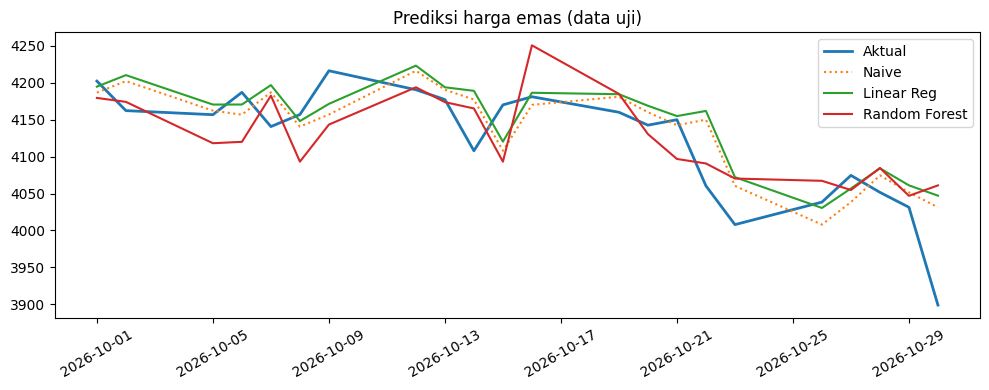

In [28]:
plt.figure(figsize=(10, 4))
plt.plot(test[COL_DATE], y_test,     label="Aktual", linewidth=2)
plt.plot(test[COL_DATE], pred_naive, label="Naive", linestyle=":")
plt.plot(test[COL_DATE], pred_lr,    label="Linear Reg")
plt.plot(test[COL_DATE], pred_rf,    label="Random Forest")
plt.legend(); plt.title("Prediksi harga emas (data uji)")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

Akurasi Arah

In [29]:
def akurasi_arah(y_true, y_pred, y_prev):
    arah_asli  = np.sign(np.asarray(y_true) - np.asarray(y_prev))
    arah_model = np.sign(np.asarray(y_pred) - np.asarray(y_prev))
    return (arah_asli == arah_model).mean() * 100

prev = X_test["lag_1"]
print(f"Akurasi arah LR: {akurasi_arah(y_test, pred_lr, prev):.1f}%")
print(f"Akurasi arah RF: {akurasi_arah(y_test, pred_rf, prev):.1f}%")

Akurasi arah LR: 40.9%
Akurasi arah RF: 54.5%


Model Selisih

In [30]:
d = df[[COL_DATE, COL_PRICE, "Set"]].copy()
d["prev"] = d[COL_PRICE].shift(1)
d["diff"] = d[COL_PRICE].diff()
for i in range(1, 4):
    d[f"dlag_{i}"] = d["diff"].shift(i)
d = d.dropna().reset_index(drop=True)

dfeat  = ["dlag_1", "dlag_2", "dlag_3"]
dtrain = d[d["Set"] == "train"]
dtest  = d[d["Set"] == "test"]

lr_d = LinearRegression().fit(dtrain[dfeat], dtrain["diff"])
pred_price = dtest["prev"] + lr_d.predict(dtest[dfeat])   # harga kemarin + perubahan prediksi

evaluasi("LR pada selisih", dtest[COL_PRICE], pred_price)
print("Naive pada baris yang sama:")
evaluasi("Naive (kemarin)", dtest[COL_PRICE], dtest["prev"])

LR pada selisih      MAE=   35.40  RMSE=   47.40
Naive pada baris yang sama:
Naive (kemarin)      MAE=   37.52  RMSE=   48.00


,prev
180,4186.7
181,4202.3
182,4162.3
183,4156.8
184,4187.1
185,4140.7
186,4157.0
187,4216.3
188,4190.6
189,4177.3
